# 🌳 Decision Trees with Scikit-Learn
### A Hands-On Worksheet — *Estimated time: 20–30 minutes*

---

In this worksheet you will:
1. Load **real-world datasets** built into scikit-learn
2. Apply a **Decision Tree Regressor** (predicting a continuous value)
3. Apply a **Decision Tree Classifier** (predicting a category)
4. Evaluate each model and tune a key hyperparameter

> 📌 **How to use this sheet:** Every cell marked `# ✏️ TODO` requires you to write or complete code. Hints are provided in the cells just above. Run each cell in order (Shift+Enter).

---
## 📦 Step 0 — Import Libraries

We need:
- `pandas` / `numpy` — data wrangling
- `sklearn` — machine learning toolkit
- `matplotlib` — visualisation

Run the cell below. You don't need to change anything here.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.figsize'] = (10, 4)

# Datasets
from sklearn.datasets import load_diabetes, load_iris

# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Decision Trees
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree

# Metrics
from sklearn.metrics import (
    mean_squared_error, r2_score,          # regression
    accuracy_score, classification_report,  # classification
    ConfusionMatrixDisplay
)

print('✅ Required libraries are ready!')

✅ Required libraries are ready!


---
# 🔵 PART 1 — Decision Tree Regression
## Dataset: Diabetes (442 patients)

**Goal:** Predict a *quantitative* measure of diabetes_data disease progression one year after baseline.

**Features (10 input variables):**  
age, sex, BMI, average blood pressure, and six blood serum measurements.

**Target:** A continuous numeric score — so this is a **regression** problem.

---

### Step 1.1 — Load & Explore the Data

🔍 **What to look for:**
- Shape: how many rows (patients) and columns (features)?
- Any missing values?
- What does the target distribution look like?

In [2]:
# Load the dataset — scikit-learn returns a Bunch object (like a dict)
diabetes_data = load_diabetes()

# Convert to a DataFrame for easy inspection
regression_features = pd.DataFrame(diabetes_data.data, columns=diabetes_data.feature_names)
regression_target = pd.Series(diabetes_data.target, name='disease_progression')

print('Data dimensions:', regression_features.shape)
print('\nPreview of the first 5 rows:')
display(regression_features.head())

print('\nFirst 5 target values:')
print(regression_target.head())

print('\nMissing entries in each column:')
print(regression_features.isnull().sum())

Data dimensions: (442, 10)

Preview of the first 5 rows:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641



First 5 target values:
0    151.0
1     75.0
2    141.0
3    206.0
4    135.0
Name: disease_progression, dtype: float64

Missing entries in each column:
age    0
sex    0
bmi    0
bp     0
s1     0
s2     0
s3     0
s4     0
s5     0
s6     0
dtype: int64


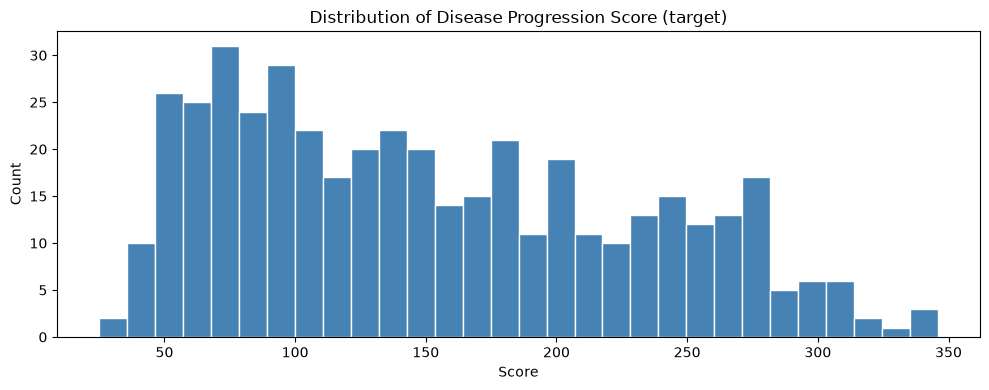

Target score range: 25 → 346  |  Average: 152.1


In [3]:
# Visualise the target distribution
plt.hist(regression_target, bins=30, color='steelblue', edgecolor='white')
plt.title('Distribution of Disease Progression Score (target)')
plt.xlabel('Score')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

print(f'Target score range: {regression_target.min():.0f} → {regression_target.max():.0f}  |  Average: {regression_target.mean():.1f}')

### Step 1.2 — Split the Data

💡 **Why split?**  
We train the model on one portion and **test** it on unseen data — otherwise we'depth_value be measuring memorisation, not learning.

A common split is **80% train / 20% test**.

---
**`train_test_split` key arguments:**
| Argument | Meaning |
|---|---|
| `test_size` | Fraction of data for testing (e.g. `0.2` = 20%) |
| `random_state` | Seed for reproducibility — any integer |


In [4]:
# ✏️ TODO: Split regression_features and regression_target into training and test sets
# Use test_size=0.2 and random_state=42

reg_train_features, reg_test_features, reg_train_target, reg_test_target = train_test_split(
    regression_features,         # features
    regression_target,         # target
    test_size=0.2,
    random_state=42
)

print(f'Samples used for training: {len(reg_train_features)}')
print(f'Samples used for testing: {len(reg_test_features)}')

Samples used for training: 353
Samples used for testing: 89


### Step 1.3 — Train the Decision Tree Regressor

💡 **Key hyperparameter — `max_depth`**  
Controls how deep the tree can grow.
- Too **shallow** → underfitting (misses patterns)
- Too **deep** → overfitting (memorises training data)

Start with `max_depth=3` for a simple, interpretable tree.

In [5]:
# ✏️ TODO: Create a DecisionTreeRegressor with max_depth=3 and random_state=42
# Then fit (train) it on the training data

regression_model = DecisionTreeRegressor(max_depth=3, random_state=42)
regression_model.fit(reg_train_features, reg_train_target)   # fit(X_train, y_train)

print('✅ Regression tree training complete!')

✅ Regression tree training complete!


### Step 1.4 — Evaluate the Regressor

**Two standard regression metrics:**

| Metric | Formula | Interpretation |
|---|---|---|
| **RMSE** (Root Mean Squared Error) | √(mean of squared errors) | Same unit as target; lower = better |
| **R²** (R-squared) | 1 − SS_res/SS_tot | 1.0 = perfect; 0 = predicts mean; <0 = worse than mean |


In [6]:
# ✏️ TODO: Use the trained model to predict on the TEST set, then compute RMSE and R²

regression_predictions = regression_model.predict(reg_test_features)   # predict on X_test_r

rmse_value = np.sqrt(mean_squared_error(reg_test_target, regression_predictions))   # (y_true, y_pred)
r2_value   = r2_score(reg_test_target, regression_predictions)                      # (y_true, y_pred)

print(f'Test RMSE: {rmse_value:.2f}')
print(f'Test R²: {r2_value:.3f}')

Test RMSE: 59.60
Test R²: 0.329


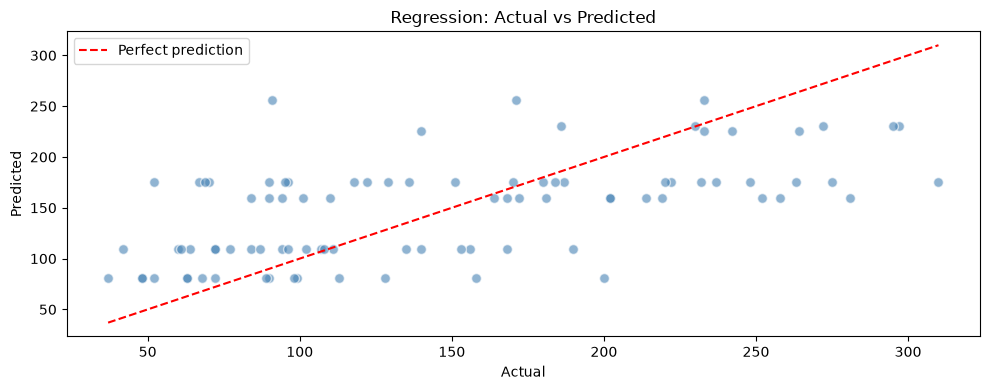

In [7]:
# Visualise: Actual vs Predicted
plt.scatter(reg_test_target, regression_predictions, alpha=0.6, color='steelblue', edgecolor='white', s=50)
score_limits = [reg_test_target.min(), reg_test_target.max()]
plt.plot(score_limits, score_limits, 'r--', label='Perfect prediction')
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Regression: Actual vs Predicted')
plt.legend()
plt.tight_layout()
plt.show()

### Step 1.5 — Visualise the Tree

One of the biggest advantages of decision trees is **interpretability** — you can literally read the rules it learned!

Each node shows:
- The **split condition** (e.g. `bmi <= 0.009`)
- **mse** — impurity at that node
- **samples** — how many training points reached this node
- **value** — the predicted value if we stopped here

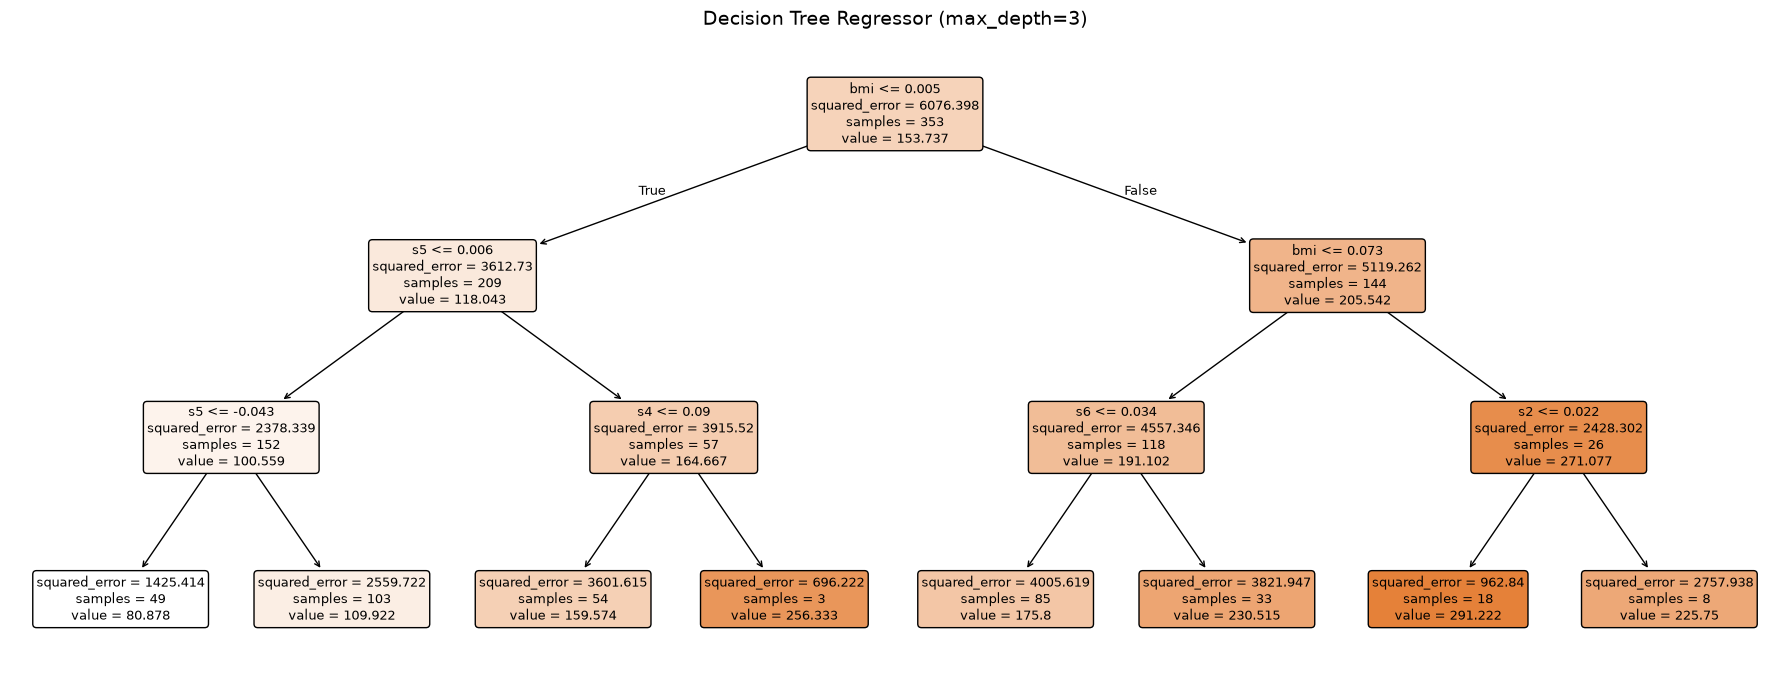

In [9]:
plot_figure, plot_axis = plt.subplots(figsize=(18, 7))
plot_tree(
    regression_model,
    feature_names=diabetes_data.feature_names,
    filled=True,
    rounded=True,
    fontsize=9,
    ax=plot_axis
)
plt.title('Decision Tree Regressor (max_depth=3)', fontsize=14)
plt.tight_layout()
plt.show()

### 🔬 Step 1.6 — Depth Experiment (Overfitting vs Underfitting)

Let's see how `max_depth` affects train vs test performance.

🧠 **What to observe:**
- Training R² always increases with depth
- Test R² peaks at some optimal depth, then **drops** (= overfitting)
- The gap between train and test R² is called the **generalisation gap**

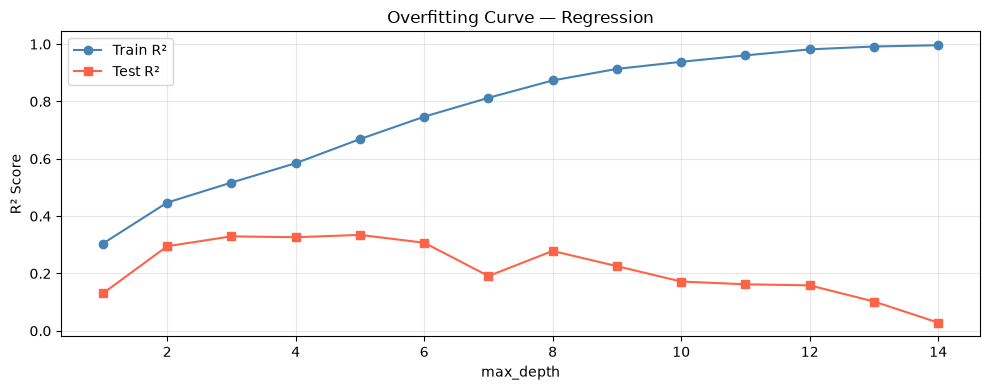

🏆 Highest test R² achieved at max_depth: 5  (R² = 0.334)


In [10]:
depth_options = range(1, 15)
training_r2_scores, testing_r2_scores = [], []

for depth_value in depth_options:
    trial_model = DecisionTreeRegressor(max_depth=depth_value, random_state=42)
    trial_model.fit(reg_train_features, reg_train_target)
    training_r2_scores.append(r2_score(reg_train_target, trial_model.predict(reg_train_features)))
    testing_r2_scores.append(r2_score(reg_test_target,  trial_model.predict(reg_test_features)))

plt.plot(depth_options, training_r2_scores, 'o-', label='Train R²', color='steelblue')
plt.plot(depth_options, testing_r2_scores,  's-', label='Test R²',  color='tomato')
plt.xlabel('max_depth')
plt.ylabel('R² Score')
plt.title('Overfitting Curve — Regression')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

optimal_depth = depth_options[np.argmax(testing_r2_scores)]
print(f'🏆 Highest test R² achieved at max_depth: {optimal_depth}  (R² = {max(testing_r2_scores):.3f})')

### ✍️ Reflection 1
Answer these questions in the cell below (as a comment or markdown):

1. At what `max_depth` did your model start overfitting? How can you tell?
2. What was the best test R² you achieved? Is this a good score for medical data?
3. Which feature appeared at the **root** (top) of the tree? Why do you think that is?

*✏️ Answers*

1. After **max_depth = 5**. Test R² peaks there (0.334) and then drops, while train R² keeps rising toward 1.0. The growing gap shows overfitting.
2. **0.334**. That's modest, but acceptable for noisy medical data with few features and samples.
3. **`bmi`**. It's the single feature that reduces error the most, and high BMI is a major driver of diabetes_data progression.

---
# 🟠 PART 2 — Decision Tree Classification
## Dataset: Iris Flowers (150 samples)

**Goal:** Classify iris_data flowers into **3 species** based on measurements.

**Features (4 input variables):**
- `sepal length (cm)`, `sepal width (cm)`
- `petal length (cm)`, `petal width (cm)`

**Target:** Species — `Setosa (0)`, `Versicolor (1)`, `Virginica (2)` → **classification** problem.

---

### Step 2.1 — Load & Explore the Data

In [11]:
iris_data = load_iris()

classification_features = pd.DataFrame(iris_data.data, columns=iris_data.feature_names)
species_target = pd.Series(iris_data.target, name='species')

print('Data dimensions:', classification_features.shape)
print('\nSpecies labels:', iris_data.target_names)
print('\nSamples per species:')
print(species_target.value_counts().rename(dict(enumerate(iris_data.target_names))))

display(classification_features.describe().round(2))

Data dimensions: (150, 4)

Species labels: ['setosa' 'versicolor' 'virginica']

Samples per species:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


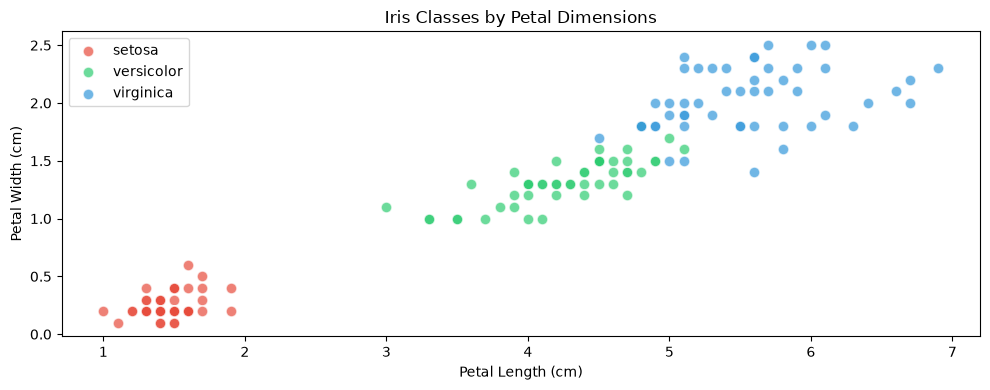

In [12]:
# Quick scatter of the two most informative features
species_colors = ['#E74C3C', '#2ECC71', '#3498DB']
for species_index in range(3):
    species_mask = species_target == species_index
    plt.scatter(
        classification_features.loc[species_mask, 'petal length (cm)'],
        classification_features.loc[species_mask, 'petal width (cm)'],
        label=iris_data.target_names[species_index],
        color=species_colors[species_index], alpha=0.7, edgecolor='white', s=60
    )
plt.xlabel('Petal Length (cm)')
plt.ylabel('Petal Width (cm)')
plt.title('Iris Classes by Petal Dimensions')
plt.legend()
plt.tight_layout()
plt.show()

### Step 2.2 — Split the Data

💡 For classification, pass `stratify=y` to `train_test_split`.  
This ensures **each class has the same proportion** in both train and test sets — important when classes are imbalanced.

In [13]:
# ✏️ TODO: Split classification_features and species_target — use test_size=0.2, random_state=42, AND stratify=species_target

clf_train_features, clf_test_features, clf_train_target, clf_test_target = train_test_split(
    classification_features,
    species_target,
    test_size=0.2,
    random_state=42,
    stratify=species_target      # keeps class balance
)

print(f'Training set: {len(clf_train_features)} samples | Testing set: {len(clf_test_features)} samples')
print('\nSpecies counts in the test set:')
print(pd.Series(clf_test_target).value_counts())

Training set: 120 samples | Testing set: 30 samples

Species counts in the test set:
species
0    10
2    10
1    10
Name: count, dtype: int64


### Step 2.3 — Train the Decision Tree Classifier

💡 **`criterion` parameter** controls how the tree measures impurity at each split:
- `'gini'` — Gini Impurity (default) — fast, works well in practice
- `'entropy'` — Information Gain — can produce slightly different trees

Both usually give similar results. We'll use `'gini'`.

In [14]:
# ✏️ TODO: Create a DecisionTreeClassifier with max_depth=3, criterion='gini', random_state=42
# Then fit it on the training data

classification_model = DecisionTreeClassifier(
    max_depth=3,
    criterion='gini',
    random_state=42
)
classification_model.fit(clf_train_features, clf_train_target)

print('✅ Classification tree training complete!')

✅ Classification tree training complete!


### Step 2.4 — Evaluate the Classifier

**Key classification metrics:**

| Metric | What it measures |
|---|---|
| **Accuracy** | % of predictions that were correct |
| **Precision** | Of all predicted positives, how many were truly positive? |
| **Recall** | Of all actual positives, how many did we catch? |
| **F1-Score** | Harmonic mean of precision & recall |

A **Confusion Matrix** shows exactly which classes the model confuses.

In [15]:
# ✏️ TODO: Predict on the test set and print accuracy and classification report

species_predictions = classification_model.predict(clf_test_features)   # predict on X_test_c

accuracy_value = accuracy_score(clf_test_target, species_predictions)     # (y_true, y_pred)

print(f'Test accuracy: {accuracy_value:.2%}\n')
print('Classification performance report:')
print(classification_report(clf_test_target, species_predictions, target_names=iris_data.target_names))

Test accuracy: 96.67%

Classification performance report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



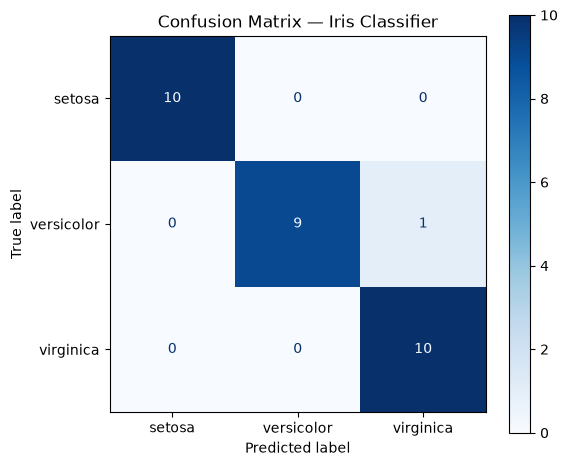

In [16]:
# Plot the Confusion Matrix
plot_figure, plot_axis = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    clf_test_target,
    species_predictions,
    display_labels=iris_data.target_names,
    cmap='Blues',
    ax=plot_axis
)
plt.title('Confusion Matrix — Iris Classifier')
plt.tight_layout()
plt.show()

### Step 2.5 — Visualise the Classification Tree

Each leaf_size node is colour-coded by class. The **darker** the shade, the **purer** the node (all samples belong to one class).

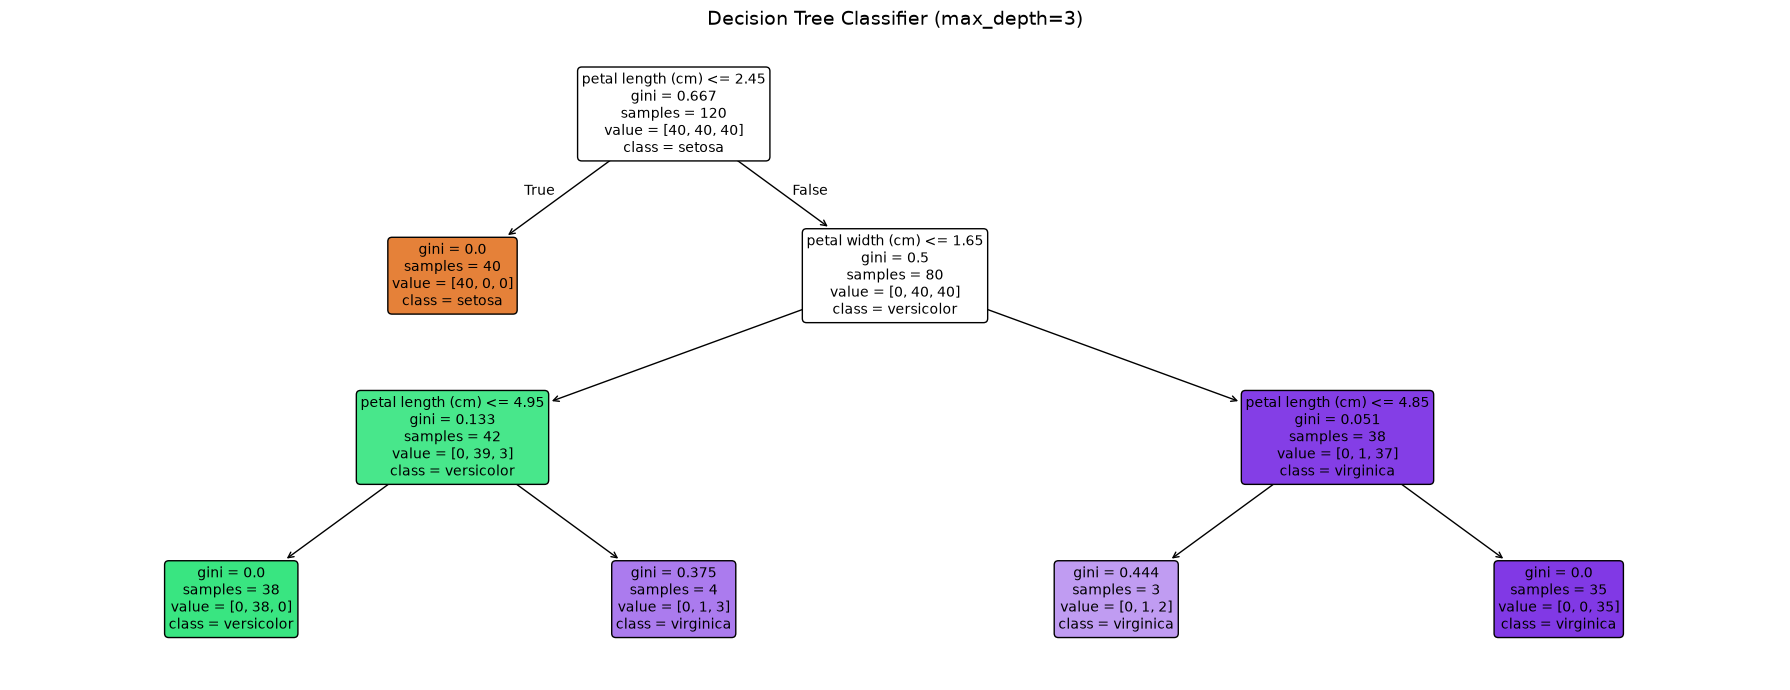

In [17]:
plot_figure, plot_axis = plt.subplots(figsize=(18, 7))
plot_tree(
    classification_model,
    feature_names=iris_data.feature_names,
    class_names=iris_data.target_names,
    filled=True,
    rounded=True,
    fontsize=10,
    ax=plot_axis
)
plt.title('Decision Tree Classifier (max_depth=3)', fontsize=14)
plt.tight_layout()
plt.show()

### Step 2.6 — Feature Importance

💡 After training, `.feature_importances_` tells you how much each feature contributed to reducing impurity across all splits.  
Values sum to 1. Higher = more important.

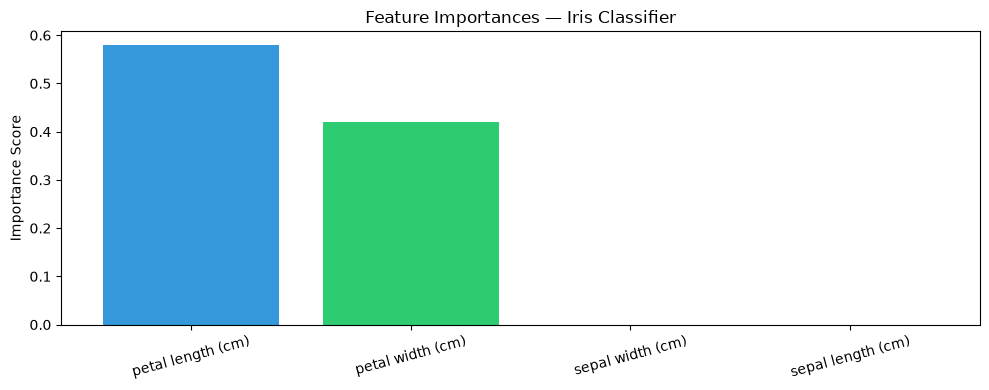

  petal length (cm)              0.5791
  petal width (cm)               0.4209
  sepal width (cm)               0.0000
  sepal length (cm)              0.0000


In [18]:
# ✏️ TODO: Extract feature importance_values and create a bar chart
# Hint: classification_model.feature_importances_ returns an array aligned with iris_data.feature_names

importance_values = classification_model.feature_importances_
feature_labels  = iris_data.feature_names

# Sort by importance (descending)
importance_order = np.argsort(importance_values)[::-1]

plt.bar(
    [feature_labels[feature_index] for feature_index in importance_order],
    importance_values[importance_order],
    color=['#3498DB', '#2ECC71', '#E74C3C', '#F39C12']
)
plt.title('Feature Importances — Iris Classifier')
plt.ylabel('Importance Score')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

for feature_index in importance_order:
    print(f'  {feature_labels[feature_index]:<30} {importance_values[feature_index]:.4f}')

### 🔬 Step 2.7 — Depth Experiment for Classification

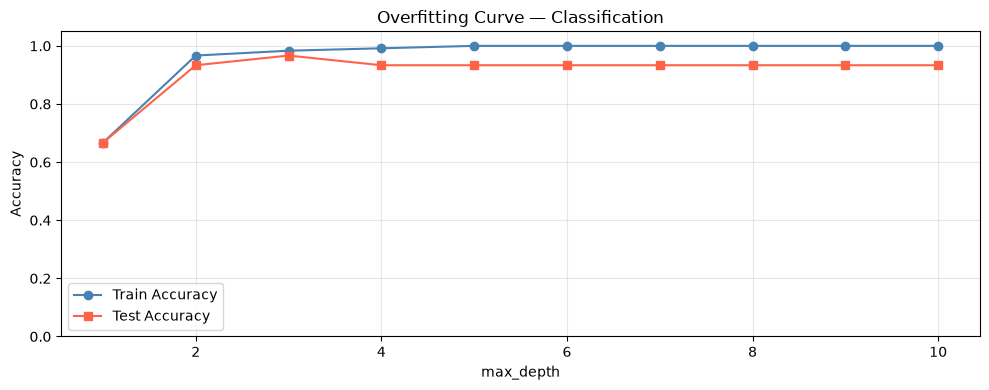

In [20]:
# ✏️ TODO: Loop over max_depth values 1–10 and record train & test accuracy
# Hint: structure is the same as the regression experiment in Step 1.6

depth_options = range(1, 11)
training_accuracies, testing_accuracies = [], []

for depth_value in depth_options:
    trial_model = DecisionTreeClassifier(max_depth=depth_value, random_state=42)
    trial_model.fit(clf_train_features, clf_train_target)
    training_accuracies.append(accuracy_score(clf_train_target, trial_model.predict(clf_train_features)))
    testing_accuracies.append(accuracy_score(clf_test_target, trial_model.predict(clf_test_features)))

plt.plot(depth_options, training_accuracies, 'o-', label='Train Accuracy', color='steelblue')
plt.plot(depth_options, testing_accuracies,  's-', label='Test Accuracy',  color='tomato')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.title('Overfitting Curve — Classification')
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### ✍️ Reflection 2

1. Which two species did the classifier confuse most? Does the scatter plot from Step 2.1 help explain why?
2. Which feature had the highest importance? Does the tree diagram confirm this?
3. At what depth did overfitting start for the classifier?

*✏️ Answers*

1. **Versicolor and Virginica**: one Versicolor was predicted as Virginica. Yes, the scatter plot shows those two overlapping, while Setosa is clearly separate.
2. **Petal length** (0.579), then petal width (0.421). Yes, the tree splits on petal length at the root.
3. After **max_depth = 3**. Test accuracy peaks there (96.7%) and drops to 93.3%, while train accuracy reaches 100%.

---
# 🌟 BONUS Challenges

Finished early? Try one or more of these:

1. **Change the criterion** — Re-train the classifier with `criterion='entropy'`. Does accuracy change?

2. **Add `min_samples_leaf`** — This prevents a node from splitting if it would create a leaf_size with fewer than N samples. Try `min_samples_leaf=5`. How does it affect overfitting?

3. **Predict a new sample** — Create a NumPy array with custom petal/sepal measurements and predict its iris_data species. Use `classification_model.predict([[...]])` and `classification_model.predict_proba([[...]])` to see class probabilities.

4. **Try a different dataset** — Replace the Iris dataset with `load_wine()` (3-class wine_data classification). Does the same `max_depth=3` tree still perform well?

In [21]:
# 🌟 Bonus workspace — write your experiments here
from sklearn.datasets import load_wine

# 1. Entropy vs Gini
entropy_model = DecisionTreeClassifier(max_depth=3, criterion='entropy', random_state=42)
entropy_model.fit(clf_train_features, clf_train_target)
print('1) Accuracy using Gini:', accuracy_score(clf_test_target, classification_model.predict(clf_test_features)))
print('   Accuracy using entropy:', accuracy_score(clf_test_target, entropy_model.predict(clf_test_features)))

# 2. min_samples_leaf (no depth limit)
for leaf_size in [1, 5]:
    trial_model = DecisionTreeClassifier(min_samples_leaf=leaf_size, random_state=42).fit(clf_train_features, clf_train_target)
    print(f'2) Minimum samples per leaf={leaf_size}: training accuracy={accuracy_score(clf_train_target, trial_model.predict(clf_train_features)):.3f}, '
          f'test={accuracy_score(clf_test_target, trial_model.predict(clf_test_features)):.3f}')

# 3. Predict a new flower [sepal len, sepal wid, petal len, petal wid]
sample_flower = np.array([[6.0, 3.0, 4.8, 1.8]])
print('3) Species predicted for the sample:', iris_data.target_names[classification_model.predict(sample_flower)[0]])
print('   Predicted class probabilities:', classification_model.predict_proba(sample_flower).round(2))

# 4. Wine dataset with the same max_depth=3 tree
wine_data = load_wine()
wine_train_features, wine_test_features, wine_train_target, wine_test_target = train_test_split(wine_data.data, wine_data.target, test_size=0.2, random_state=42, stratify=wine_data.target)
wine_model = DecisionTreeClassifier(max_depth=3, random_state=42).fit(wine_train_features, wine_train_target)
print('4) Test accuracy on the wine dataset:', round(accuracy_score(wine_test_target, wine_model.predict(wine_test_features)), 3))

1) Accuracy using Gini: 0.9666666666666667
   Accuracy using entropy: 0.9666666666666667
2) Minimum samples per leaf=1: training accuracy=1.000, testing accuracy=0.933
2) Minimum samples per leaf=5: training accuracy=0.967, testing accuracy=0.933
3) Species predicted for the sample: virginica
   Predicted class probabilities: [[0.   0.33 0.67]]
4) Test accuracy on the wine dataset: 0.944


c:\Users\HP\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\Users\HP\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


*✏️ Bonus answers*

1. **No change**: entropy and gini both give 96.7%.
2. Train accuracy drops from 100% to 96.7% and test stays at 93.3%, so the tree memorises less and overfits less.
3. `[6.0, 3.0, 4.8, 1.8]` is predicted as **virginica** (67% virginica, 33% versicolor).
4. **Yes**: the wine_data data reaches 94.4% test accuracy with the same depth-3 tree.

---
## 📋 Summary Cheat-Sheet

| | Regression | Classification |
|---|---|---|
| **Class** | `DecisionTreeRegressor` | `DecisionTreeClassifier` |
| **Loss/criterion** | `mse` (default) | `gini` or `entropy` |
| **Key metrics** | RMSE, R² | Accuracy, F1, Confusion Matrix |
| **Overfitting check** | Train R² ↑ while Test R² ↓ | Train Acc ↑ while Test Acc ↓ |
| **Main hyperparameter** | `max_depth` | `max_depth` |

**Workflow (always the same):**
```
Load data → Split → Instantiate model → .fit() → .predict() → Evaluate → Tune
```

> 🚀 Next steps: **Random Forests** (many trees voting together) dramatically reduce overfitting — try `sklearn.ensemble.RandomForestClassifier`!